# TUAB meta features — what do we know about the patients and recordings?

The fine-tuning task only ever sees **EEG windows + a binary normal/abnormal label**.
This notebook takes stock of everything *else* we know about each recording, and asks
whether any of it is useful for training or prediction.

**Sources of meta information (all read-only):**

| Source | What it gives | How |
|---|---|---|
| Directory layout | normal/abnormal label, official train/eval split | path |
| EDF patient field | **age**, **sex**, subject id | `labram/data/tuh_metadata.py` |
| EDF recording field | **session number** (patient's n-th TUH EEG), **year**, equipment tag | same |
| EDF signal headers | sampling rate, amplifier range, channel inventory (EKG, EMG, EOG, photic, **sphenoidal electrodes**) | `labram/data/tuh_meta_features.py` |
| Auxiliary channels | **heart rate / HRV** from the EKG lead, **photic stimulation** performed, device-computed **burst-suppression trends** | same |
| The EEG itself | **signal quality** (clipping, flat/noisy electrodes, artifacts, mains noise) and **qEEG** summaries (slowing, posterior dominant rhythm, asymmetry, sharp transients) | same |
| Processed windows | which recordings made it into `processed/` and which split | `processed_npy/manifest.json` |

The per-recording table is built once by
`python dataset_maker/make_TUAB_meta.py --root <edf dir>` (≈25 min, 8 cores) and cached as
`processed/meta_features.csv`; this notebook only loads and analyses it.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from labram.eval.meta_analysis import (
    FEATURE_GROUPS, SIGNATURES, add_derived_columns, available_features,
    metadata_baseline, signature_flags, univariate_auc,
)

EDF_ROOT = Path("/data/datasets/EEG-public/TAUB/TUH_Abnormal/v3.0.0/edf")
META_CSV = EDF_ROOT / "processed" / "meta_features.csv"
MANIFEST = EDF_ROOT / "processed_npy" / "manifest.json"
NPY_DIR = EDF_ROOT / "processed_npy" / "recordings"

# Plot conventions: one fixed colour per class, recessive grid, no top/right spines.
C_NORMAL, C_ABNORMAL, C_NEUTRAL = "#2a78d6", "#eb6834", "#8a8984"
CLASS_COLORS = {"normal": C_NORMAL, "abnormal": C_ABNORMAL}
GROUP_COLORS = dict(zip(FEATURE_GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]))
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "legend.frameon": False,
})
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 3)

In [2]:
df = pd.read_csv(META_CSV)
df["error"] = df["error"].fillna("")
df = add_derived_columns(df)

manifest = json.loads(MANIFEST.read_text())
proc = pd.DataFrame(manifest["recordings"])[["stem", "source_split", "n_windows"]]
df = df.merge(proc.rename(columns={"source_split": "processed_split"}), on="stem", how="left")
df["in_processed"] = df["processed_split"].notna()

print(f"{len(df)} recordings, {df['subject'].nunique()} subjects, {df.shape[1]} columns")
print(f"extraction errors: {(df['error'] != '').sum()}")
pd.crosstab([df["tuh_split"], df["label"]], df["processed_split"].fillna("— not processed —"), margins=True)

2993 recordings, 2329 subjects, 63 columns
extraction errors: 0


processed_split     test  train  val  — not processed —   All
tuh_split label                                              
eval      abnormal   126      0    0                  0   126
          normal     150      0    0                  0   150
train     abnormal     0   1052  291                  3  1346
          normal       0   1090  281                  0  1371
All                  276   2142  572                  3  2993

## 1. Inventory — which meta features exist, and how complete are they?

Coverage = share of the 2,993 recordings where the feature has a value. A feature can
be missing because the channel was not recorded (EMG, photic), because the device did
not compute it (burst-suppression trends), or because it is a sentinel (age 999 = 90+).

In [3]:
SOURCE = {
    "demographics": "EDF patient field", "history": "EDF recording field",
    "acquisition": "EDF signal headers / photic channel", "quality": "EEG signal",
    "physiology": "EKG lead / device trend channels", "qeeg": "EEG signal",
}
inv = []
for group, cols in FEATURE_GROUPS.items():
    for c in cols:
        if c not in df:
            continue
        s = df[c]
        inv.append({"group": group, "feature": c, "source": SOURCE[group],
                    "coverage_%": 100 * s.notna().mean(), "n_unique": s.nunique(),
                    "example": s.dropna().iloc[0] if s.notna().any() else None})
inventory = pd.DataFrame(inv)
inventory.style.format({"coverage_%": "{:.1f}"}).background_gradient(
    subset=["coverage_%"], cmap="Blues", vmin=0, vmax=100).hide(axis="index")

group,feature,source,coverage_%,n_unique,example
demographics,age,EDF patient field,99.5,84,75.000000
demographics,sex_male,EDF patient field,100.0,2,0.000000
history,session_number,EDF recording field,100.0,27,3.000000
history,year,EDF recording field,100.0,8,2012.000000
acquisition,duration_min,EDF signal headers / photic channel,100.0,707,20.283333
acquisition,sfreq,EDF signal headers / photic channel,100.0,3,250.000000
acquisition,physical_max_uv,EDF signal headers / photic channel,100.0,2,4999.847000
acquisition,n_signals,EDF signal headers / photic channel,100.0,9,30.000000
acquisition,has_emg,EDF signal headers / photic channel,100.0,2,0.000000
acquisition,has_eog,EDF signal headers / photic channel,100.0,2,1.000000


In [4]:
missing = pd.Series({
    "Age missing / sentinel (999 = 90+, 0)": df["age"].isna().sum(),
    "Sex missing": df["sex"].isna().sum(),
    "No EKG channel": (~df["has_ekg"].astype(bool)).sum(),
    "EKG present but no usable heart rate": (df["has_ekg"].astype(bool) & df["ekg_hr_bpm"].isna()).sum(),
    "No EMG channel": (df["has_emg"] == 0).sum(),
    "No photic channel": (df["has_photic_channel"] == 0).sum(),
    "Photic channel but no stimulation": ((df["has_photic_channel"] == 1) & (df["photic_performed"] == 0)).sum(),
    "Burst-suppression trend not computed": df["trend_suppr_mean"].isna().sum(),
    "EDF not in processed windows": (~df["in_processed"]).sum(),
}, name="recordings")
missing.to_frame().assign(**{"%": lambda t: 100 * t["recordings"] / len(df)})

,recordings,%
"Age missing / sentinel (999 = 90+, 0)",15,0.501
Sex missing,0,0.000
No EKG channel,0,0.000
EKG present but no usable heart rate,0,0.000
No EMG channel,1179,39.392
No photic channel,157,5.246
Photic channel but no stimulation,680,22.720
Burst-suppression trend not computed,1187,39.659
EDF not in processed windows,3,0.100


**What is *not* in the data at all** — worth stating explicitly, because it bounds every
question below:

| Wanted | Available? |
|---|---|
| **Reason the EEG is abnormal** (slowing, epileptiform discharges, seizure, …) | ❌ TUAB labels are binary. TUH stopped distributing the EEG reports, which held the findings. |
| Diagnosis, medications, indication for the EEG, ICU status | ❌ (only in the withdrawn reports) |
| Race/ethnicity, handedness, height/weight | ❌ |
| Vigilance state (awake/drowsy/asleep), eyes open/closed events | ❌ not annotated in TUAB (only indirectly: photic stimulation, PDR prominence) |
| Exact recording date / time of day | ❌ anonymised to 01-JAN-YYYY 00:00 — only the **year** survives |
| Per-recording label confidence | ⚠️ corpus-level only: the AAREADME reports 27 train files (1%) where the annotator disagreed with the report, but not *which* |

## 2. Demographics — age, sex, and patient history

age                                         
           count  mean   std  min   25%   50%   75%   max
label                                                    
abnormal  1463.0  54.4  17.2  1.0  44.0  55.0  67.0  89.0
normal    1515.0  44.0  16.1  1.0  31.0  44.0  55.0  88.0

label,abnormal,normal
share by sex,,
F,0.465,0.535
M,0.522,0.478


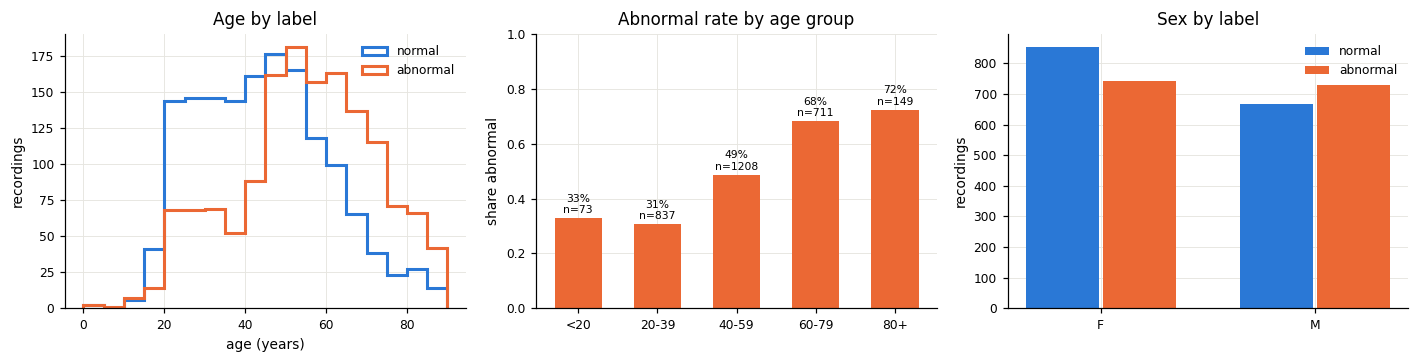

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
bins = np.arange(0, 95, 5)
for lab in ["normal", "abnormal"]:
    axes[0].hist(df.loc[df.label == lab, "age"].dropna(), bins=bins, histtype="step", lw=2,
                 color=CLASS_COLORS[lab], label=lab)
axes[0].set(title="Age by label", xlabel="age (years)", ylabel="recordings"); axes[0].legend()

rate = df.groupby("age_group", observed=True)["is_abnormal"].agg(["mean", "size"])
axes[1].bar(rate.index.astype(str), rate["mean"], color=C_ABNORMAL, width=0.6)
for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    axes[1].text(i, m + 0.01, f"{m:.0%}\nn={n}", ha="center", va="bottom", fontsize=7)
axes[1].set(title="Abnormal rate by age group", ylabel="share abnormal", ylim=(0, 1))

sx = pd.crosstab(df["sex"], df["label"])
x = np.arange(len(sx))
for j, lab in enumerate(["normal", "abnormal"]):
    axes[2].bar(x + (j - 0.5) * 0.36, sx[lab], width=0.34, color=CLASS_COLORS[lab], label=lab)
axes[2].set_xticks(x, sx.index); axes[2].set(title="Sex by label", ylabel="recordings"); axes[2].legend()
plt.tight_layout()

display(df.groupby("label")[["age"]].describe().round(1))
display(pd.crosstab(df["sex"], df["label"], normalize="index").round(3).rename_axis("share by sex"))

subjects with >1 recording: 443 / 2329;  subjects with BOTH a normal and an abnormal recording: 54


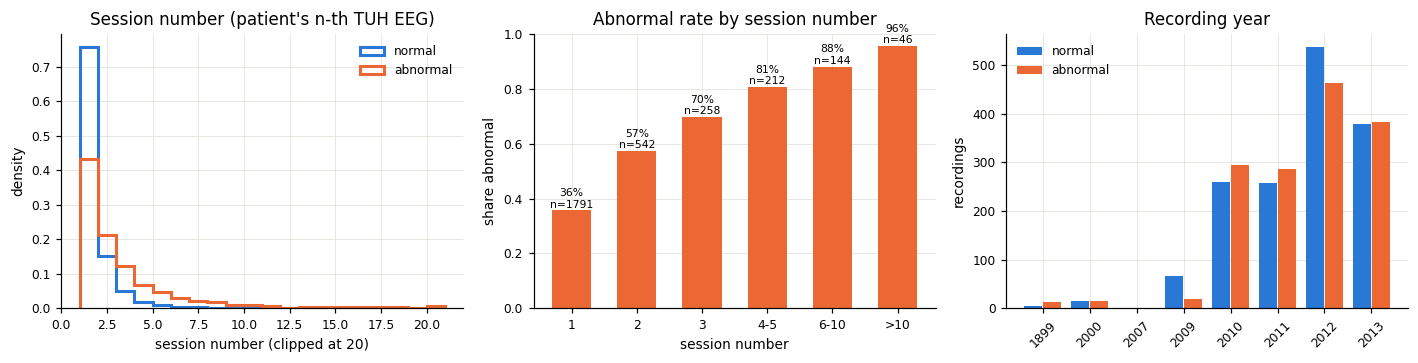

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
sn = df["session_number"].clip(upper=20)
for lab in ["normal", "abnormal"]:
    axes[0].hist(sn[df.label == lab], bins=np.arange(1, 22), histtype="step", lw=2,
                 color=CLASS_COLORS[lab], label=lab, density=True)
axes[0].set(title="Session number (patient's n-th TUH EEG)", xlabel="session number (clipped at 20)",
            ylabel="density"); axes[0].legend()

sb = df.assign(sbin=pd.cut(df["session_number"], [0, 1, 2, 3, 5, 10, 1000],
                           labels=["1", "2", "3", "4-5", "6-10", ">10"]))
r = sb.groupby("sbin", observed=True)["is_abnormal"].agg(["mean", "size"])
axes[1].bar(r.index.astype(str), r["mean"], color=C_ABNORMAL, width=0.6)
for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
    axes[1].text(i, m + 0.01, f"{m:.0%}\nn={n}", ha="center", fontsize=7)
axes[1].set(title="Abnormal rate by session number", ylabel="share abnormal", ylim=(0, 1),
            xlabel="session number")

yr = pd.crosstab(df["year"], df["label"])
x = np.arange(len(yr))
for j, lab in enumerate(["normal", "abnormal"]):
    axes[2].bar(x + (j - 0.5) * 0.4, yr[lab], width=0.38, color=CLASS_COLORS[lab], label=lab)
axes[2].set_xticks(x, yr.index, rotation=45); axes[2].set(title="Recording year", ylabel="recordings")
axes[2].legend(); plt.tight_layout()

per_subj = df.groupby("subject").agg(n=("stem", "size"), labels=("label", "nunique"))
print(f"subjects with >1 recording: {(per_subj.n > 1).sum()} / {len(per_subj)};  "
      f"subjects with BOTH a normal and an abnormal recording: {(per_subj.labels > 1).sum()}")

## 3. Acquisition setup — real information or a shortcut?

These describe *how* the EEG was recorded. If the abnormal rate differs strongly between
values, a model can learn the hospital workflow (which room / amplifier / protocol was used
for sicker patients) instead of brain activity. For LaBraM this matters less — it only sees
19 resampled channels — but **sampling rate and amplifier range survive preprocessing**
as subtle spectral/amplitude fingerprints.

In [7]:
cat_cols = ["sfreq", "physical_max_uv", "equipment_tag", "n_signals", "has_emg", "has_eog",
            "has_sphenoidal", "has_numbered_extra", "photic_performed"]
rows = []
for c in cat_cols:
    for val, g in df.groupby(c, dropna=False):
        rows.append({"feature": c, "value": val, "recordings": len(g),
                     "abnormal_rate": g["is_abnormal"].mean(),
                     "eval_share": (g["tuh_split"] == "eval").mean()})
acq = pd.DataFrame(rows)
overall = df["is_abnormal"].mean()
acq.style.format({"abnormal_rate": "{:.0%}", "eval_share": "{:.0%}"}).background_gradient(
    subset=["abnormal_rate"], cmap="RdBu_r", vmin=0, vmax=2 * overall).hide(axis="index")

feature,value,recordings,abnormal_rate,eval_share
sfreq,250.000000,2786,48%,10%
sfreq,256.000000,189,71%,4%
sfreq,512.000000,18,33%,0%
physical_max_uv,4999.847000,2786,48%,10%
physical_max_uv,5482.288000,207,68%,4%
equipment_tag,#,28,82%,7%
equipment_tag,#####,116,60%,4%
equipment_tag,Compact_32ch,22,86%,0%
equipment_tag,Compact_64ch,14,64%,0%
equipment_tag,X,2813,48%,10%


## 4. Data quality — is the data good, noisy, or missing?

Per recording, over the 19 scalp electrodes (10-s epochs, 0.5–45 Hz):

* **clipping** — samples at ≥99% of the amplifier range (saturation)
* **flat epoch** — any electrode with std < 0.5 µV (disconnected)
* **high-amplitude epoch** — any electrode with peak-to-peak > 500 µV (movement, electrode pop)
* **bad epoch** = flat or high-amplitude; **noisy channel** = overall amplitude a >5 MAD outlier
* **mains noise** — power at 60 ± 1 Hz (and 50 ± 1 Hz) relative to 1–45 Hz, log10

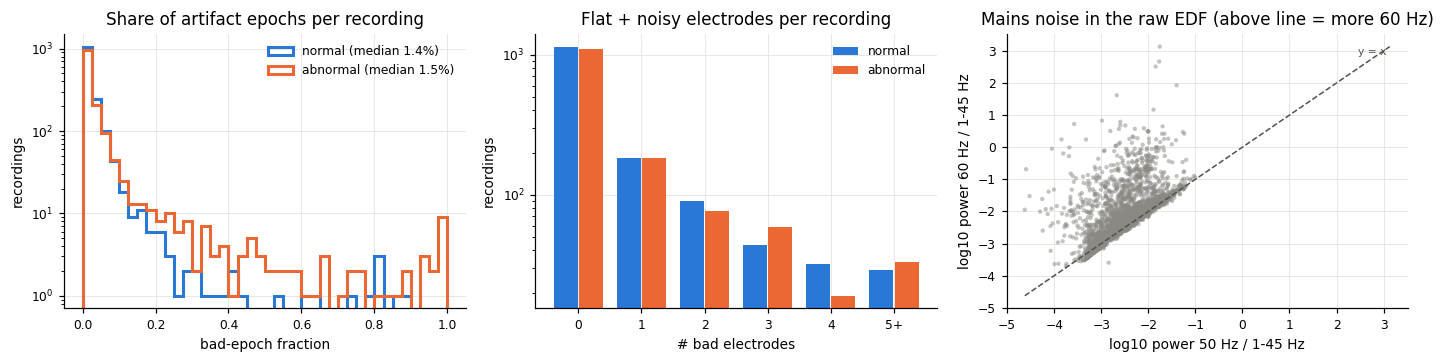

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for lab in ["normal", "abnormal"]:
    s = df.loc[df.label == lab, "q_bad_epoch_frac"]
    axes[0].hist(s, bins=np.linspace(0, 1, 41), histtype="step", lw=2, color=CLASS_COLORS[lab],
                 label=f"{lab} (median {s.median():.1%})")
axes[0].set(title="Share of artifact epochs per recording", xlabel="bad-epoch fraction",
            ylabel="recordings", yscale="log"); axes[0].legend()

ch = df.assign(bad_ch=(df["q_n_flat_channels"] + df["q_n_noisy_channels"]).clip(upper=5))
t = pd.crosstab(ch["bad_ch"], ch["label"])
x = np.arange(len(t))
for j, lab in enumerate(["normal", "abnormal"]):
    axes[1].bar(x + (j - 0.5) * 0.4, t[lab], width=0.38, color=CLASS_COLORS[lab], label=lab)
axes[1].set_xticks(x, [str(i) if i < 5 else "5+" for i in t.index])
axes[1].set(title="Flat + noisy electrodes per recording", xlabel="# bad electrodes", ylabel="recordings",
            yscale="log"); axes[1].legend()

axes[2].scatter(df["q_line50_log_ratio"], df["q_line60_log_ratio"], s=8, alpha=0.5, color=C_NEUTRAL,
                edgecolor="none")
lim = [min(df["q_line50_log_ratio"].min(), df["q_line60_log_ratio"].min()),
       max(df["q_line50_log_ratio"].max(), df["q_line60_log_ratio"].max())]
axes[2].plot(lim, lim, color="#52514e", lw=1, ls="--")
axes[2].text(lim[1], lim[1], "y = x ", fontsize=7, color="#52514e", va="top", ha="right")
axes[2].set(title="Mains noise in the raw EDF (above line = more 60 Hz)", xlabel="log10 power 50 Hz / 1-45 Hz",
            ylabel="log10 power 60 Hz / 1-45 Hz")
plt.tight_layout()

In [9]:
def tier(r):
    if r.q_n_flat_channels >= 2 or r.q_bad_epoch_frac > 0.3 or r.q_clip_frac > 0.01:
        return "poor"
    if r.q_n_flat_channels + r.q_n_noisy_channels >= 1 or r.q_bad_epoch_frac > 0.1:
        return "fair"
    return "good"

df["quality_tier"] = df.apply(tier, axis=1)
display(pd.crosstab([df["tuh_split"], df["label"]], df["quality_tier"], margins=True)[["good", "fair", "poor", "All"]])
print("Worst recordings by artifact share:")
df.sort_values("q_bad_epoch_frac", ascending=False)[
    ["stem", "label", "tuh_split", "age", "q_bad_epoch_frac", "q_clip_frac", "q_n_flat_channels",
     "q_n_noisy_channels", "q_median_amp_uv", "duration_min"]].head(10)

[output not saved: it lists individual TUH recordings (id, label, age). Re-run locally to see it;
 per-recording TUH data stays out of git under the data-use agreement.]


### Does the preprocessing remove the mains noise?

`dataset_maker/make_TUAB.py` band-passes 0.1–75 Hz and applies a **50 Hz** notch. TUH was
recorded in Philadelphia, where the mains frequency is **60 Hz** — so the notch misses it
and the 75 Hz low-pass keeps it. Checked directly on a sample of the processed windows
the model trains on:

60 Hz peak vs 55-58 Hz floor: median x2.2, >10x in 17% of sampled recordings


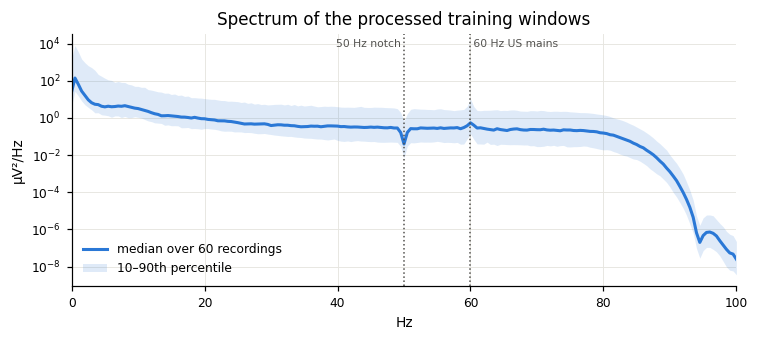

In [10]:
from scipy.signal import welch
rng = np.random.default_rng(0)
sample = rng.choice(df.loc[df.in_processed, "stem"].to_numpy(), size=60, replace=False)
psds = []
for stem in sample:
    x = np.load(NPY_DIR / f"{stem}.npy", mmap_mode="r")[: 200 * 300]      # first 5 min
    f, p = welch(np.asarray(x, dtype=np.float64), fs=200, nperseg=400, axis=0)
    psds.append(p.mean(axis=1))
psds = np.array(psds)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.semilogy(f, np.median(psds, axis=0), color=C_NORMAL, lw=2, label="median over 60 recordings")
ax.fill_between(f, np.percentile(psds, 10, axis=0), np.percentile(psds, 90, axis=0), color=C_NORMAL,
                alpha=0.15, lw=0, label="10–90th percentile")
for f0, txt, ha in [(50, "50 Hz notch ", "right"), (60, " 60 Hz US mains", "left")]:
    ax.axvline(f0, color="#52514e", lw=1, ls=":")
    ax.text(f0, ax.get_ylim()[1] * 0.2, txt, fontsize=7, ha=ha, color="#52514e")
ax.set(title="Spectrum of the processed training windows", xlabel="Hz", ylabel="µV²/Hz", xlim=(0, 100))
ax.legend(); plt.tight_layout()
i60, ibase = np.argmin(abs(f - 60)), (f > 55) & (f < 58)
ratio = psds[:, i60] / psds[:, ibase].mean(axis=1)
print(f"60 Hz peak vs 55-58 Hz floor: median x{np.median(ratio):.1f}, "
      f">10x in {(ratio > 10).mean():.0%} of sampled recordings")

## 5. Why is a case abnormal?

TUAB does not say. The clinical reasons for an "abnormal" EEG read are, in rough order of
frequency: **background slowing** (diffuse or focal), a **slow or absent posterior dominant
rhythm**, **asymmetry**, **epileptiform discharges** (spikes/sharp waves), and rarer patterns
(burst-suppression, low voltage). Most of these have a quantitative EEG proxy, so we can
recover a *putative* reason per recording:

* each signature is a qEEG feature + the direction in which it becomes abnormal;
* the threshold is the 95th (or 5th) percentile of **normal training recordings in the same
  age group** — so ~5% of normals are flagged by construction, and age effects (the PDR slows
  with age) don't masquerade as abnormality.

These are *screening phenotypes*, not diagnoses — epileptiform discharges in particular are
brief and rarely move a whole-recording statistic.

,normal,abnormal,lift,feature
diffuse_slowing,5.1%,49.9%,x9.8,qeeg_slowing_ratio
slow_pdr,3.8%,27.9%,x7.3,qeeg_pdr_freq
focal_slowing,5.3%,29.7%,x5.6,qeeg_max_delta_asymmetry
asymmetry,5.5%,21.9%,x4.0,qeeg_max_asymmetry
absent_pdr,4.8%,11.5%,x2.4,qeeg_pdr_prominence
sharp_transients,5.6%,3.7%,x0.7,qeeg_median_kurtosis
low_voltage,5.4%,2.9%,x0.5,qeeg_log_total_power


abnormal recordings with NO signature: 28%  (normals with none: 73%)


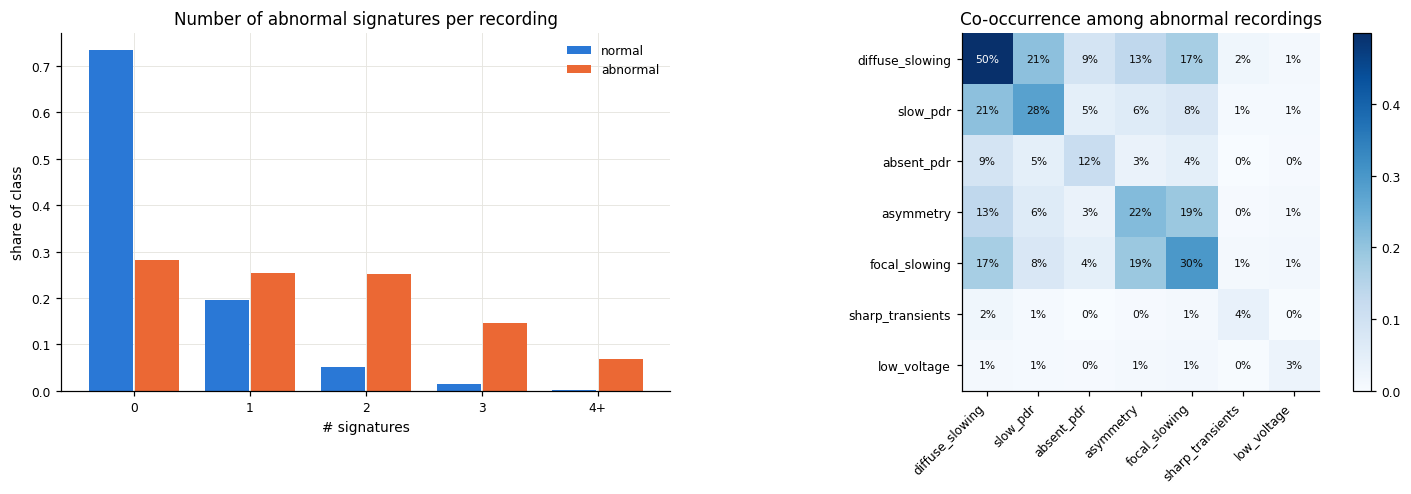

In [11]:
reference = (df["label"] == "normal") & (df["tuh_split"] == "train")
flags = signature_flags(df, reference)
prev = pd.DataFrame({
    lab: flags[df["label"] == lab].mean() for lab in ["normal", "abnormal"]
}).assign(lift=lambda t: t["abnormal"] / t["normal"].clip(lower=1e-3))
prev["feature"] = [SIGNATURES[s][0] for s in prev.index]
display(prev.sort_values("lift", ascending=False).style.format(
    {"normal": "{:.1%}", "abnormal": "{:.1%}", "lift": "x{:.1f}"}))

n_sig = flags.sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
t = pd.crosstab(n_sig.clip(upper=4), df["label"], normalize="columns")
x = np.arange(len(t))
for j, lab in enumerate(["normal", "abnormal"]):
    axes[0].bar(x + (j - 0.5) * 0.4, t[lab], width=0.38, color=CLASS_COLORS[lab], label=lab)
axes[0].set_xticks(x, [str(i) if i < 4 else "4+" for i in t.index])
axes[0].set(title="Number of abnormal signatures per recording", xlabel="# signatures",
            ylabel="share of class"); axes[0].legend()

ab = flags[df["label"] == "abnormal"]
co = (ab.T.astype(int) @ ab.astype(int)) / len(ab)
im = axes[1].imshow(co, cmap="Blues", vmin=0)
axes[1].set_xticks(range(len(co)), co.columns, rotation=45, ha="right")
axes[1].set_yticks(range(len(co)), co.index); axes[1].grid(False)
for i in range(len(co)):
    for j in range(len(co)):
        axes[1].text(j, i, f"{co.iloc[i, j]:.0%}", ha="center", va="center", fontsize=7,
                     color="white" if co.iloc[i, j] > co.values.max() * 0.6 else "#0b0b0b")
axes[1].set_title("Co-occurrence among abnormal recordings")
plt.colorbar(im, ax=axes[1], fraction=0.04); plt.tight_layout()
print(f"abnormal recordings with NO signature: {(n_sig[df.label == 'abnormal'] == 0).mean():.0%}  "
      f"(normals with none: {(n_sig[df.label == 'normal'] == 0).mean():.0%})")

In [12]:
# The dominant phenotype per abnormal recording = the signature it violates most strongly
# (largest exceedance in reference-SD units), for a readable "reason" column.
z = pd.DataFrame(index=df.index)
for name, (col, direction) in SIGNATURES.items():
    ref = df.loc[reference, col]
    s = (df[col] - ref.median()) / ref.std()
    z[name] = s if direction == "high" else -s
df["putative_reason"] = np.where(flags.any(axis=1), z.where(flags, -np.inf).idxmax(axis=1), "none detected")
reason = pd.crosstab(df["putative_reason"], df["label"])
reason = reason.loc[reason["abnormal"].sort_values(ascending=False).index]
display(reason.assign(**{"abnormal %": lambda t: 100 * t["abnormal"] / t["abnormal"].sum()}).round(1))

label,abnormal,normal,abnormal %
putative_reason,,,
diffuse_slowing,519,66,35.3
none detected,414,1117,28.1
focal_slowing,264,64,17.9
slow_pdr,117,43,7.9
asymmetry,76,63,5.2
sharp_transients,36,77,2.4
low_voltage,28,60,1.9
absent_pdr,18,31,1.2


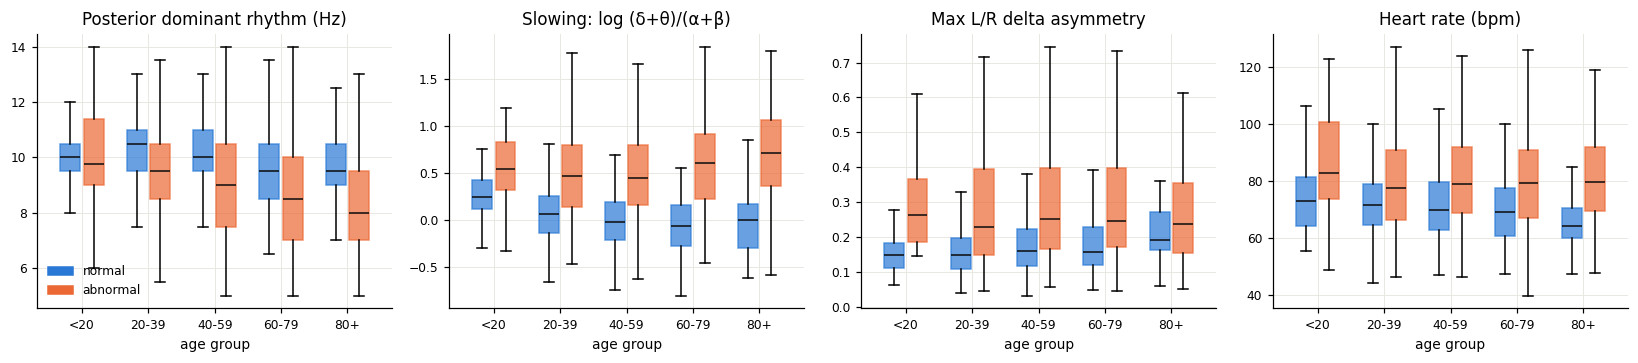

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (col, title) in zip(axes, [
    ("qeeg_pdr_freq", "Posterior dominant rhythm (Hz)"),
    ("qeeg_slowing_ratio", "Slowing: log (δ+θ)/(α+β)"),
    ("qeeg_max_delta_asymmetry", "Max L/R delta asymmetry"),
    ("ekg_hr_bpm", "Heart rate (bpm)"),
]):
    groups = df["age_group"].cat.categories
    pos = np.arange(len(groups))
    for j, lab in enumerate(["normal", "abnormal"]):
        data = [df.loc[(df.age_group == g) & (df.label == lab), col].dropna() for g in groups]
        bp = ax.boxplot(data, positions=pos + (j - 0.5) * 0.35, widths=0.3, showfliers=False,
                        patch_artist=True, medianprops=dict(color="#0b0b0b"))
        for b in bp["boxes"]:
            b.set(facecolor=CLASS_COLORS[lab], alpha=0.7, edgecolor=CLASS_COLORS[lab])
    ax.set_xticks(pos, groups); ax.set(title=title, xlabel="age group")
axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=C_NORMAL), plt.Rectangle((0, 0), 1, 1, color=C_ABNORMAL)],
               ["normal", "abnormal"])
plt.tight_layout()

### Clinical-context hints hidden in the setup

Some acquisition details are indirect evidence of *why the patient was referred*:
**sphenoidal electrodes** are placed for temporal-lobe epilepsy work-ups; a high **session
number** means a patient with many EEGs (chronic neurological follow-up); a device-computed
**burst-suppression trend** with sustained suppression points to an ICU / encephalopathy
context.

In [14]:
ctx = pd.DataFrame({
    "sphenoidal electrodes": df["has_sphenoidal"] == 1,
    "session number > 5": df["session_number"] > 5,
    "suppression > 50% for >5% of record": df["trend_suppr_gt50_frac"] > 0.05,
    "photic stimulation done": df["photic_performed"] == 1,
    "no photic stimulation": df["photic_performed"] == 0,
})
pd.DataFrame({
    "recordings": ctx.sum(),
    "abnormal_rate": [df.loc[m, "is_abnormal"].mean() for m in ctx.T.values],
}).style.format({"abnormal_rate": "{:.0%}"})

,recordings,abnormal_rate
sphenoidal electrodes,105,63%
session number > 5,190,90%
suppression > 50% for >5% of record,1319,25%
photic stimulation done,2156,37%
no photic stimulation,837,80%


## 6. Can the meta features be used for training or prediction?

Two questions:

1. **How much label information is in each feature on its own?** (univariate ROC-AUC on the
   training split, 0.5 = none)
2. **How well does metadata *alone* predict normal/abnormal?** Gradient-boosted trees trained
   on TUAB train, scored on the official, subject-disjoint TUAB eval set, one feature group at
   a time.

> **Comparing with LaBraM.** The published LaBraM-Base TUAB numbers (AUROC 0.902, balanced
> accuracy 0.814) are **per 10-s window**. The baselines here are **per recording**, which is an
> easier unit: a whole-recording statistic averages out noise that a single window cannot.
> For a like-for-like comparison, use the recording-level (case-aggregated) LaBraM metrics
> from `notebooks/finetune_evaluation.ipynb`.

,feature,group,auc,direction,coverage,median_normal,median_abnormal
0,qeeg_theta_alpha_ratio,qeeg,0.820,higher=abnormal,1.000,-0.230,0.201
1,qeeg_slowing_ratio,qeeg,0.813,higher=abnormal,1.000,0.020,0.518
2,qeeg_aperiodic_slope,qeeg,0.795,lower=abnormal,1.000,-1.273,-1.892
3,qeeg_rel_beta,qeeg,0.775,lower=abnormal,1.000,0.184,0.092
4,qeeg_rel_alpha,qeeg,0.774,lower=abnormal,1.000,0.255,0.119
5,qeeg_rel_delta,qeeg,0.751,higher=abnormal,1.000,0.353,0.551
6,qeeg_max_delta_asymmetry,qeeg,0.728,higher=abnormal,1.000,0.155,0.248
7,qeeg_log_total_power,qeeg,0.703,higher=abnormal,1.000,1.761,2.012
8,qeeg_pdr_freq,qeeg,0.688,lower=abnormal,1.000,10.000,9.000
9,session_number,history,0.685,higher=abnormal,1.000,1.000,2.000


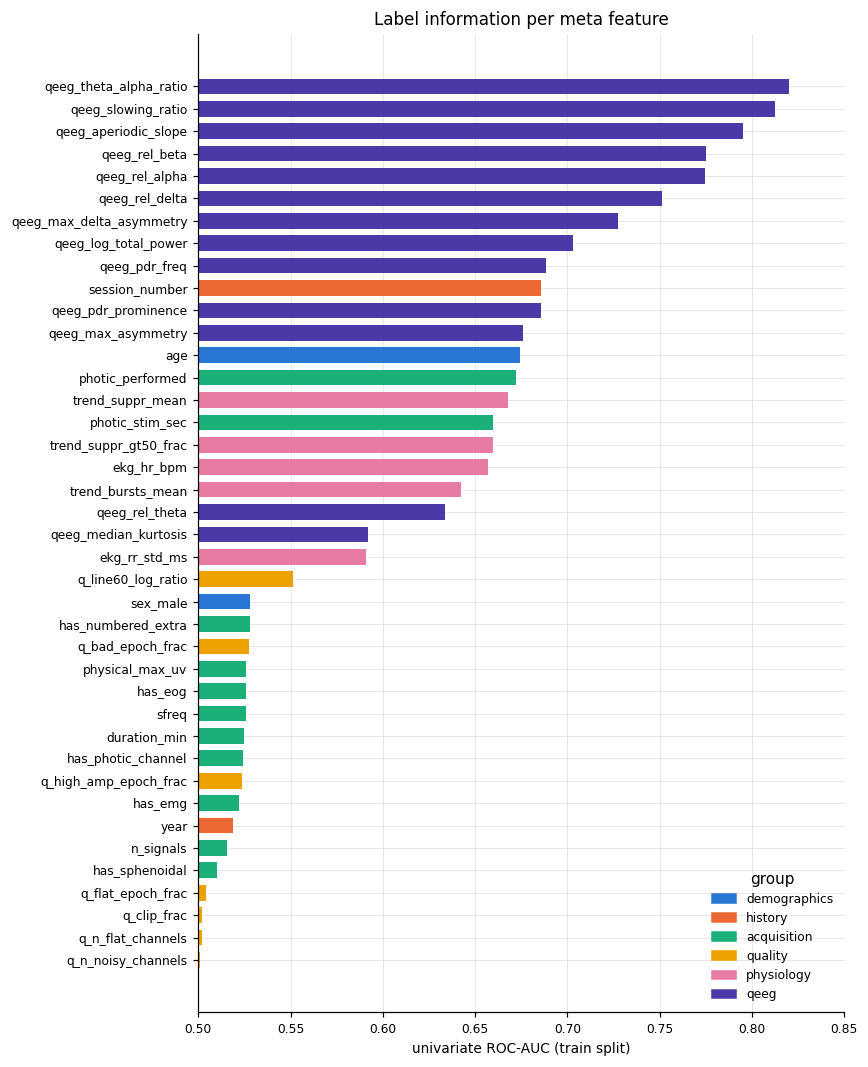

In [15]:
train = df[df.tuh_split == "train"]
test = df[df.tuh_split == "eval"]
uni = univariate_auc(train, available_features(df))
fig, ax = plt.subplots(figsize=(8, 0.22 * len(uni) + 1))
ax.barh(uni["feature"][::-1], uni["auc"][::-1] - 0.5, left=0.5,
        color=[GROUP_COLORS[g] for g in uni["group"][::-1]], height=0.7)
ax.axvline(0.5, color="#52514e", lw=1)
ax.set(xlim=(0.5, max(0.85, uni["auc"].max() + 0.02)), xlabel="univariate ROC-AUC (train split)",
       title="Label information per meta feature")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()], GROUP_COLORS.keys(),
          loc="lower right", title="group")
plt.tight_layout()
uni.head(15)

In [16]:
experiments = {
    "demographics (age, sex)": ["demographics"],
    "+ history (session no., year)": ["demographics", "history"],
    "acquisition only": ["acquisition"],
    "quality only": ["quality"],
    "physiology only (EKG, trends)": ["physiology"],
    "qEEG only": ["qeeg"],
    "demographics + qEEG": ["demographics", "qeeg"],
    "all meta features": list(FEATURE_GROUPS),
    "all except acquisition/history": ["demographics", "quality", "physiology", "qeeg"],
}
results, models = [], {}
for name, groups in experiments.items():
    feats = available_features(df, groups)
    m, model = metadata_baseline(train, test, feats)
    results.append({"features": name, **m}); models[name] = (model, feats)
res = pd.DataFrame(results).set_index("features")
display(res.style.format({"auroc": "{:.3f}", "balanced_acc": "{:.3f}"}).bar(
    subset=["auroc"], vmin=0.5, vmax=1.0, color="#a8c8ef"))

,auroc,balanced_acc,n_features
features,,,
"demographics (age, sex)",0.689,0.639,2
"+ history (session no., year)",0.727,0.644,4
acquisition only,0.686,0.658,11
quality only,0.574,0.575,7
"physiology only (EKG, trends)",0.783,0.721,5
qEEG only,0.890,0.813,13
demographics + qEEG,0.901,0.832,15
all meta features,0.922,0.863,40
all except acquisition/history,0.907,0.831,27


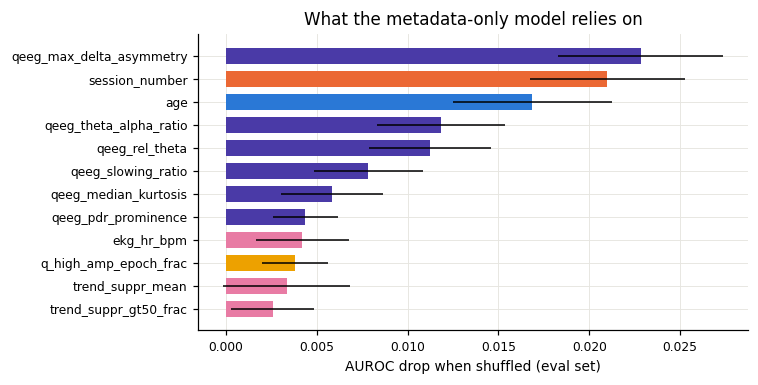

In [17]:
from sklearn.inspection import permutation_importance
model, feats = models["all meta features"]
pi = permutation_importance(model, test[feats].astype(float), test["is_abnormal"], scoring="roc_auc",
                            n_repeats=10, random_state=0)
imp = pd.DataFrame({"feature": feats, "auroc_drop": pi.importances_mean, "std": pi.importances_std}) \
        .sort_values("auroc_drop", ascending=False).head(12)
imp["group"] = [next(g for g, c in FEATURE_GROUPS.items() if f in c) for f in imp["feature"]]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(imp["feature"][::-1], imp["auroc_drop"][::-1], xerr=imp["std"][::-1],
        color=[GROUP_COLORS[g] for g in imp["group"][::-1]], height=0.7, error_kw=dict(lw=1))
ax.set(xlabel="AUROC drop when shuffled (eval set)", title="What the metadata-only model relies on")
plt.tight_layout()

### Relevance for the age-regression task

For the brain-age task (`TUAB_AGE`), the interesting question is the reverse: which meta
features *track age* — these are what a brain-age model will implicitly learn, and the
non-EEG ones (heart rate, session number) are covariates to control for. Spearman ρ within
**normal** recordings only, so pathology doesn't drive it:

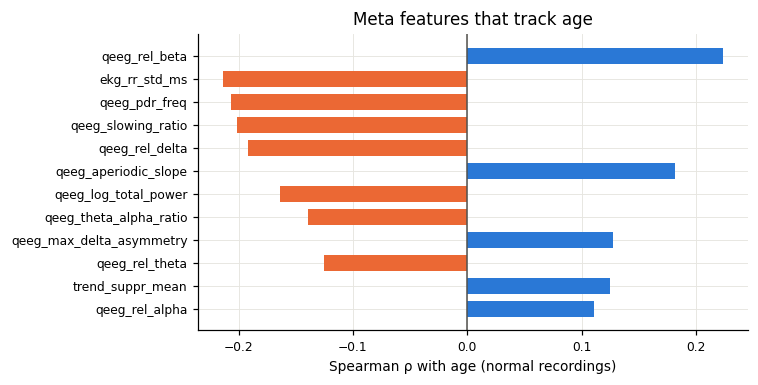

In [18]:
normals = df[df.label == "normal"]
feats = [f for f in available_features(df) if f != "age"]
rho = normals[feats + ["age"]].corr(method="spearman")["age"].drop("age").dropna()
rho = rho.reindex(rho.abs().sort_values(ascending=False).index).head(12)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(rho.index[::-1], rho.values[::-1], color=[C_NORMAL if v > 0 else C_ABNORMAL for v in rho.values[::-1]],
        height=0.7)
ax.axvline(0, color="#52514e", lw=1)
ax.set(xlabel="Spearman ρ with age (normal recordings)", title="Meta features that track age")
plt.tight_layout()

## 7. Findings and recommendations

Numbers are from the full TUAB v3.0.0 sweep (2,993 recordings, 2,329 subjects, 0 extraction failures).

### What meta information exists

| | coverage | note |
|---|---|---|
| Age | 99.5% | 15 unusable: 12 × `Age:999` (90+, redacted), 3 × `Age:0` |
| Sex | 100% | |
| Session number, recording year | 100% | year **1899** (16 recordings) and **2000** (29) are placeholder dates; treat as missing |
| Heart rate / HRV (EKG lead) | 100% | an EKG lead exists on every recording; R-peaks detected in all |
| Photic stimulation | 95% have the channel; performed in 72% | |
| Device burst-suppression trends | 60% | computed only by some acquisition systems |
| EMG / sphenoidal electrodes | 61% / 3.5% | |
| **Reason for abnormality, diagnosis, medication, vigilance** | **0%** | not distributed by TUH |

### Demographics

* Abnormal patients are **~10 years older** (mean 54.4 vs 44.0). The abnormal rate climbs from 31% (age 20–39) to 72% (80+).
* Sex is nearly balanced: 52% of male recordings are abnormal, vs 47% of female ones.
* 443 subjects have more than one recording, and **54 have both a normal and an abnormal one**.
* **Session number is a strong proxy for illness.** 36% of first EEGs are abnormal, rising to 81% at sessions 4–5 and 96% after more than 10 sessions.

### Data quality

* **The data is mostly clean.** Clipping is essentially absent, and the median recording has 1.4% artifact epochs. Quality tiers: **2,116 good / 791 fair / 86 poor**.
* **Poor quality concentrates in abnormal recordings.** Train has 64 poor abnormal recordings vs 15 poor normal ones; very ill and ICU patients produce more artifact.
* A handful of recordings are essentially unusable: 100% artifact epochs, or 6–8 dead electrodes (a few train recordings and one *eval* recording; cell 14 lists them when run locally). All of them are labelled abnormal, so every window they contribute teaches "noise = abnormal".
* **Mains noise is not removed.** `make_TUAB.py` notches 50 Hz, but TUH is US data with 60 Hz mains. In the processed training windows the 60 Hz peak is a median ×2.2 above the neighbouring floor, and over ×10 in 17% of recordings.
* 3 abnormal train EDFs never made it into the processed windows.

### Why is a case abnormal? (putative, from qEEG)

| signature | abnormal | normal |
|---|---|---|
| diffuse slowing | **50%** | 5% |
| focal (delta) asymmetry | **30%** | 5% |
| slow posterior rhythm | **28%** | 4% |
| hemispheric asymmetry | **22%** | 6% |
| absent posterior rhythm | 12% | 5% |
| sharp transients (kurtosis), low voltage | 3–4% | 5–6% (no signal) |

* **72% of abnormal recordings show at least one signature**, vs 27% of normals. Many show several: slowing and slow PDR co-occur, and so do focal slowing and asymmetry.
* **28% of abnormal recordings show none.** These are most likely epileptiform-only abnormalities (brief spikes that whole-recording spectra cannot see), subtle findings, or label noise. They should be the hardest cases for any model.
* The kurtosis "spike" proxy does **not** work: kurtosis is *higher* in normals, because it is dominated by eye blinks and alpha bursts. Recovering epileptiform reasons needs event annotations (TUEV) or a TUEV-trained detector.
* **Context hints:** recordings *without* photic stimulation are **80% abnormal** (837 recordings), vs 37% with it. Sphenoidal electrodes mean 63% abnormal. More than 5 sessions means 90% abnormal.
* The device `SUPPR` trend is *higher* in normals (median 68% vs 30%). It is therefore **not** a clinical burst-suppression percentage; its semantics are unknown, so do not interpret it clinically.

### Can the meta features be used? Metadata-only model, recording level, official eval set

| features | AUROC | bal. acc |
|---|---|---|
| demographics (age, sex) | 0.689 | 0.639 |
| + history (session number, year) | 0.727 | 0.644 |
| acquisition only | 0.686 | 0.658 |
| quality only | 0.574 | 0.575 |
| physiology only (EKG, trends) | 0.783 | 0.721 |
| **qEEG only** | **0.890** | **0.813** |
| demographics + qEEG | 0.901 | 0.832 |
| patient-level (all except acquisition/history) | 0.907 | 0.831 |
| all meta features | 0.922 | 0.863 |

13 hand-crafted spectral summaries plus age already recover most of the TUAB label. In practice the label mostly means "background slowing or asymmetry beyond what is normal for this age". That makes a **strong, cheap baseline** that LaBraM has to beat at the *recording* level.

### Recommendations

1. **Use age (and sex) as inputs.** They are legitimately known at prediction time, and normal EEG ranges are age-dependent. The simplest route is late fusion: concatenate them to the pooled embedding before the head, or stack them on the case-level LaBraM score.
2. **Run a stacking experiment:** a gradient-boosted model on LaBraM's recording-level probability + qEEG + age. If it beats LaBraM alone, the encoder is missing information. If not, LaBraM has already absorbed it.
3. **Do not feed acquisition/history features to the model** (photic performed, session number, device tags, trend availability, sampling rate). They encode Temple's referral workflow and will not transfer to another hospital. **Do use them to stratify evaluation**: check LaBraM within photic yes/no and first-session vs repeat subgroups. A large drop within strata means the model learned the workflow.
4. **Use the putative reasons for error analysis and auxiliary targets.** Measure recall per phenotype, especially on the 28% of abnormals with no signature. Regressing slowing ratio / PDR as an auxiliary head is a cheap multi-task regularizer.
5. **Clean the data.** Drop or down-weight the 86 poor-tier recordings, or mask their bad epochs. Add a 60 Hz notch: this needs a reprocessing pass, and should be checked against the pre-trained checkpoint, which saw the same 60 Hz residue. Treat years 1899/2000 as missing.
6. **To get real abnormality reasons,** request the annotated TUH subcorpora (TUEV events, TUSZ seizures, TUSL slowing, TUEP epilepsy, TUAR artifacts) and join them to TUAB by subject id. They are not on disk or in S3 today, and the id overlap still has to be verified once they are downloaded.